# ASOS Product Analysis: Stockouts, Size Availability, and Brand Strategy

## Objective
Assess product and size availability across ASOS listings, estimate a **price-based stockout exposure proxy**, identify brands and products that warrant inventory review, and translate the findings into actionable inventory recommendations.

## Analytical questions
1. How widespread are size-level stockouts across the analyzed listings?
2. Which sizes and products show the greatest availability pressure?
3. Which brands combine higher average prices with elevated stockout rates?
4. Which products should be prioritized for inventory investigation?



In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import re
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")


In [15]:
#Source file
candidate_paths = [
    Path("/content/products_asos.csv"),  # Google Colab
    Path("products_asos.csv"),           # same folder
]
csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find products_asos.csv. Upload the CSV and update csv_path."
    )

df = pd.read_csv(csv_path, on_bad_lines="skip")

required_columns = {"price", "name", "size", "description"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"]).copy()
df["description"] = df["description"].fillna("").astype(str)
df["name"] = df["name"].fillna("").astype(str)
df["size"] = df["size"].fillna("").astype(str)

print(f"Source file: {csv_path}")
print(f"Rows retained after valid-price filter: {len(df):,}")
print(f"Columns available: {list(df.columns)}")

display(df.head())


Source file: /content/products_asos.csv
Rows retained after valid-price filter: 18,378
Columns available: ['url', 'name', 'size', 'category', 'price', 'color', 'sku', 'description', 'images']


,url,name,size,category,price,color,sku,description,images
0,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,"126,704,571.00",[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
1,https://www.asos.com/stradivarius/stradivarius...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,"126,704,571.00",[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
2,https://www.asos.com/asos-design/asos-design-l...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,"126,704,571.00",[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
3,https://www.asos.com/new-look/new-look-trench-...,New Look trench coat in camel,"UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...",New Look trench coat in camel,49.99,Neutral,"126,704,571.00",[{'Product Details': 'Coats & Jackets by New L...,['https://images.asos-media.com/products/new-l...
4,https://www.asos.com/stradivarius/stradivarius...,Stradivarius double breasted wool coat in grey,"XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14",Stradivarius double breasted wool coat in grey,59.99,GREY,"123,650,194.00",[{'Product Details': 'Coats & Jackets by Strad...,['https://images.asos-media.com/products/strad...


In [5]:
def get_brand(text):
    text = str(text)
    match = re.search(r"\bby\s+(.+?)(?:[|,.()]|$)", text, flags=re.IGNORECASE)
    if match:
        candidate = match.group(1).strip()
        # Keep the extracted phrase, then normalize known truncated/concatenated labels below.
        return candidate
    return "Unknown"

df["brand_raw"] = df["description"].apply(get_brand)

brand_map = {
    "New": "New Look",
    "River": "River Island",
    "Miss": "Miss Selfridge",
    "TopshopWelcome": "Topshop",
    "New Look": "New Look",
    "River Island": "River Island",
    "Miss Selfridge": "Miss Selfridge",
    "Topshop": "Topshop",
}

df["Brand"] = df["brand_raw"].replace(brand_map)
df.loc[df["Brand"].str.strip().eq(""), "Brand"] = "Unknown"

brand_quality = (
    df["Brand"].value_counts(dropna=False)
      .rename_axis("Brand")
      .reset_index(name="Listing_Rows")
)
print("Most frequent extracted brand labels:")
display(brand_quality.head(20))

print("Unknown/unresolved brand share: "
      f"{df['Brand'].eq('Unknown').mean():.2%}")


Most frequent extracted brand labels:


,Brand,Listing_Rows
0,Y,95
1,Mama,56
2,ASOS DESIGNLow effort,32
3,ASOS DESIGN Thanks,27
4,ASOS DESIGNIf in doubt,21
5,ASOS DESIGNThanks,17
6,OnlyThrow on,16
7,ASOS DESIGNDramatic entrance,15
8,StradivariusThrow on,15
9,ASOS DESIGNThrow on,14


Unknown/unresolved brand share: 0.00%


In [6]:
# Retaining brands with more than five listing rows

brand_counts = df["Brand"].value_counts()
valid_brands = brand_counts[brand_counts > 5].index
df_clean = df[df["Brand"].isin(valid_brands)].copy()

print(f"Rows retained after brand-frequency filter: {len(df_clean):,}")
print(f"Distinct brand labels retained: {df_clean['Brand'].nunique():,}")
display(df_clean["Brand"].value_counts().head(20).rename("Listing_Rows").to_frame())


Rows retained after brand-frequency filter: 531
Distinct brand labels retained: 37


,Listing_Rows
Brand,
Y,95
Mama,56
ASOS DESIGNLow effort,32
ASOS DESIGN Thanks,27
ASOS DESIGNIf in doubt,21
ASOS DESIGNThanks,17
OnlyThrow on,16
ASOS DESIGNDramatic entrance,15
StradivariusThrow on,15


In [7]:
# Calculate listing-row stockout metrics and a price-based exposure proxy.

def count_stockouts(size_str):
    """Return (total listed size options, sold-out size options) for one row."""
    if not isinstance(size_str, str) or not size_str.strip():
        return 0, 0
    entries = [x.strip() for x in size_str.split(",") if x.strip()]
    total_sizes = len(entries)
    sold_out = sum("out of stock" in x.lower() for x in entries)
    return total_sizes, sold_out

size_counts = df_clean["size"].apply(count_stockouts)
df_clean["Total_Sizes"] = size_counts.str[0]
df_clean["Stockout_Count"] = size_counts.str[1]

# Rows without size information cannot be classified.
df_clean = df_clean[df_clean["Total_Sizes"] > 0].copy()
df_clean["Stockout_Rate"] = (
    df_clean["Stockout_Count"] / df_clean["Total_Sizes"]
).clip(0, 1)


df_clean["Revenue_At_Risk"] = df_clean["price"] * df_clean["Stockout_Count"]

print(f"Analyzable listing rows: {len(df_clean):,}")
print(f"Rows with a URL column: {'url' in df_clean.columns}")


Analyzable listing rows: 531
Rows with a URL column: True


In [8]:
# Overall availability summary (listing-row and size-option measures)

total_size_options = df_clean["Total_Sizes"].sum()
sold_out_size_options = df_clean["Stockout_Count"].sum()

summary = pd.DataFrame({
    "Metric": [
        "Analyzed listing rows",
        "Average stockout rate per listing row",
        "Share of all listed size options sold out",
        "Share of listing rows with at least one sold-out size",
        "Price-based stockout exposure proxy"
    ],
    "Value": [
        f"{len(df_clean):,}",
        f"{df_clean['Stockout_Rate'].mean():.2%}",
        f"{sold_out_size_options / total_size_options:.2%}" if total_size_options else "N/A",
        f"{(df_clean['Stockout_Count'] > 0).mean():.2%}",
        f"{df_clean['Revenue_At_Risk'].sum():,.2f}"
    ]
})
display(summary)

# Top five listing rows by exposure proxy
cols = ["Brand", "name", "price", "Stockout_Count",
        "Stockout_Rate", "Revenue_At_Risk"]
top5 = (
    df_clean.sort_values("Revenue_At_Risk", ascending=False)[cols]
    .head(5).reset_index(drop=True)
)
display(top5.style.format({
    "price": "{:,.2f}",
    "Stockout_Rate": "{:.2%}",
    "Revenue_At_Risk": "{:,.2f}"
}))


,Metric,Value
0,Analyzed listing rows,531
1,Average stockout rate per listing row,23.81%
2,Share of all listed size options sold out,24.21%
3,Share of listing rows with at least one sold-o...,49.91%
4,Price-based stockout exposure proxy,"49,408.65"


,Brand,name,price,Stockout_Count,Stockout_Rate,Revenue_At_Risk
0,The North FaceStand out,The North Face 1996 Retro Nuptse down jacket in lilac paint print,300.00,4,80.00%,"1,200.00"
1,ASOS DESIGNDramatic entrance,ASOS DESIGN embellished plunge mini dress in ombre beaded fringe in taupe,165.00,7,87.50%,"1,155.00"
2,ASOS EDITIONIf in doubt,ASOS EDITION sequin and faux feather fringe midi dress in lilac,205.00,5,62.50%,"1,025.00"
3,ASOS LuxeIf in doubt,ASOS LUXE embellished sequin mini dress with heart back cut out & feather trim in pink,100.00,7,87.50%,700.00
4,The North FaceStand out,The North Face Saikuru puffer jacket in blue,215.00,3,60.00%,645.00


In [9]:
# Determine whether exposure is concentrated in a small number of listing rows.

top5_total = top5["Revenue_At_Risk"].sum()
total_risk = df_clean["Revenue_At_Risk"].sum()
top5_share = top5_total / total_risk if total_risk else np.nan

print(f"Top-five exposure proxy: {top5_total:,.2f}")
print(f"Share of total exposure proxy: {top5_share:.2%}" if pd.notna(top5_share)
      else "No exposure proxy recorded.")


Top-five exposure proxy: 4,725.00
Share of total exposure proxy: 9.56%


Unique product identifiers after consolidation: 525
Product identifiers represented by multiple rows: 6
Top 10 brands by average stockout rate (minimum 11 unique products):


,Brand,Product_Count,Listing_Rows,Avg_Price,Avg_Stockout_Rate,Exposure_Proxy
26,Pull&BearThrow on,13,13,48.38,50.77%,"1,627.70"
5,ASOS DESIGN Thanks,27,27,39.96,37.96%,"3,074.00"
7,ASOS DESIGNDramatic entrance,15,15,66.00,35.00%,"2,658.00"
10,ASOS DESIGNThanks,17,17,41.53,30.88%,"2,243.00"
29,StradivariusThrow on,15,15,67.92,28.00%,"1,155.79"
8,ASOS DESIGNIf in doubt,21,21,85.67,26.19%,"3,575.00"
11,ASOS DESIGNThrow on,14,14,56.00,25.00%,"1,809.00"
9,ASOS DESIGNLow effort,32,32,26.09,25.00%,"1,803.00"
16,Mama,56,56,31.11,24.70%,"2,289.00"
35,Y,91,95,78.21,19.27%,"6,876.00"


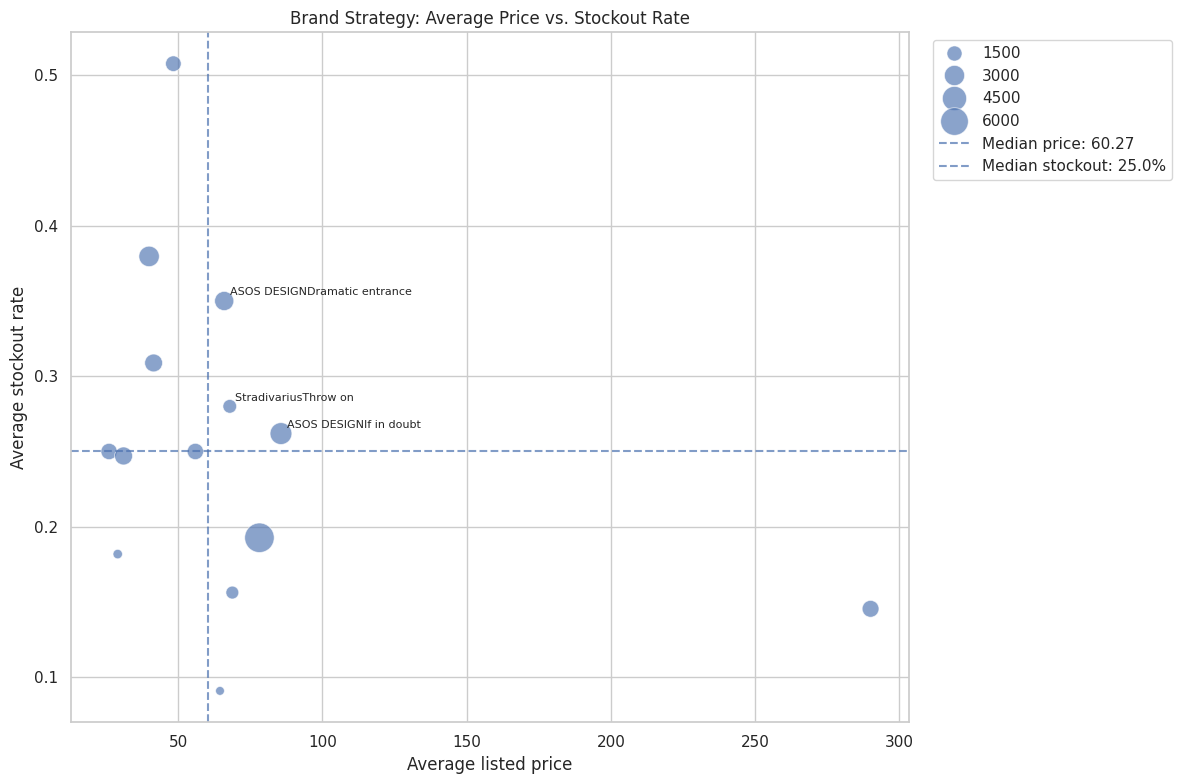

Interpretation: brands in the upper-right quadrant combine above-median average prices and above-median stockout rates.


In [11]:
# Product-level consolidation and brand strategy analysis.

product_source = df_clean.copy()
if "url" in product_source.columns:
    product_source["Product_ID"] = product_source["url"].fillna("").astype(str).str.strip()
    empty_id = product_source["Product_ID"].eq("")
    product_source.loc[empty_id, "Product_ID"] = (
        product_source.loc[empty_id, "Brand"].astype(str) + "|" +
        product_source.loc[empty_id, "name"].astype(str) + "|" +
        product_source.loc[empty_id, "price"].astype(str)
    )
else:
    product_source["Product_ID"] = (
        product_source["Brand"].astype(str) + "|" +
        product_source["name"].astype(str) + "|" +
        product_source["price"].astype(str)
    )

product_analysis = (
    product_source.groupby("Product_ID", dropna=False)
    .agg(
        Brand=("Brand", "first"),
        name=("name", "first"),
        Avg_Price=("price", "mean"),
        Listing_Rows=("name", "size"),
        Avg_Stockout_Rate=("Stockout_Rate", "mean"),
        Exposure_Proxy=("Revenue_At_Risk", "mean"),
        Size_Options_Observed=("Total_Sizes", "mean"),
        Sold_Out_Size_Records=("Stockout_Count", "mean")
    )
    .reset_index()
)

print(f"Unique product identifiers after consolidation: {len(product_analysis):,}")
print(f"Product identifiers represented by multiple rows: "
      f"{(product_analysis['Listing_Rows'] > 1).sum():,}")

# Brand metrics are calculated from the consolidated product table.
brand_strategy = (
    product_analysis.groupby("Brand")
    .agg(
        Avg_Price=("Avg_Price", "mean"),
        Avg_Stockout_Rate=("Avg_Stockout_Rate", "mean"),
        Exposure_Proxy=("Exposure_Proxy", "sum"),
        Product_Count=("Product_ID", "nunique"),
        Listing_Rows=("Listing_Rows", "sum")
    )
    .reset_index()
)

# Exclude brands with very small product samples from brand comparison.
brand_strategy = brand_strategy[brand_strategy["Product_Count"] > 10].copy()

top10_brands = brand_strategy.sort_values(
    ["Avg_Stockout_Rate", "Exposure_Proxy"], ascending=False
).head(10)

print("Top 10 brands by average stockout rate (minimum 11 unique products):")
display(top10_brands[[
    "Brand", "Product_Count", "Listing_Rows", "Avg_Price",
    "Avg_Stockout_Rate", "Exposure_Proxy"
]].style.format({
    "Avg_Price": "{:,.2f}",
    "Avg_Stockout_Rate": "{:.2%}",
    "Exposure_Proxy": "{:,.2f}"
}))

plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=brand_strategy,
    x="Avg_Price",
    y="Avg_Stockout_Rate",
    size="Exposure_Proxy",
    sizes=(40, 450),
    alpha=0.65
)

price_threshold = brand_strategy["Avg_Price"].median()
stockout_threshold = brand_strategy["Avg_Stockout_Rate"].median()
plt.axvline(price_threshold, linestyle="--", alpha=0.7,
            label=f"Median price: {price_threshold:.2f}")
plt.axhline(stockout_threshold, linestyle="--", alpha=0.7,
            label=f"Median stockout: {stockout_threshold:.1%}")

priority_brands = brand_strategy[
    (brand_strategy["Avg_Price"] >= price_threshold) &
    (brand_strategy["Avg_Stockout_Rate"] >= stockout_threshold)
].nlargest(8, "Exposure_Proxy")

for _, row in priority_brands.iterrows():
    plt.annotate(
        row["Brand"],
        (row["Avg_Price"], row["Avg_Stockout_Rate"]),
        xytext=(4, 4), textcoords="offset points", fontsize=8
    )

plt.title("Brand Strategy: Average Price vs. Stockout Rate")
plt.xlabel("Average listed price")
plt.ylabel("Average stockout rate")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print(
    "Interpretation: brands in the upper-right quadrant combine above-median "
    "average prices and above-median stockout rates."
)


# *KEY FINDINGS*

1. High-priced products can still experience significant availability problems. ASOS DESIGN Dramatic entrance, Stradivarius, and ASOS DESIGN If in doubt all exceed the median stockout rate despite having above-median prices.

2. Affordable brands should not be overlooked. Pull&BearThrow on has the highest stockout rate among the identified brands, despite being below the median price.

3. Lower stockout rates do not necessarily mean lower financial exposure. Y demonstrates how a larger product assortment can contribute to substantial aggregate exposure.

4. Inventory prioritization requires multiple performance indicators. Average price, stockout rate, product count, and estimated financial exposure should be considered together.

#*SUMMARY*

The brand strategy analysis examined the relationship between average listed product prices and average stockout rates to identify potential inventory management priorities across brands. The scatter plot utilized median reference values of 60.27 for average price and 25.0% for average stockout rate, dividing the brands into four strategic categories.

The results identified several brands in the upper-right quadrant, representing above-median average prices and above-median stockout rates. These included ASOS DESIGN Dramatic entrance, with an average price of 66.00 and a stockout rate of 35.00%; Stradivarius, with an average price of 67.92 and a stockout rate of 28.00%; and ASOS DESIGN If in doubt, with an average price of 85.67 and a stockout rate of 26.19%. These brands represent potential priorities for inventory investigation because of their relatively higher prices and elevated stockout rates.

Meanwhile, Pull&Bear demonstrated a particularly high stockout rate of 50.77%, despite having an average price of 48.38, which falls below the median price. This finding indicates that product availability concerns are not exclusive to higher-priced brands and may also affect more affordable product segments.

Conversely, Y recorded an average stockout rate of 19.27%, below the median threshold, despite having the highest exposure proxy among the ten brands examined, amounting to 6,876.00. This suggests that aggregate financial exposure should also be considered when evaluating inventory performance, as brands with larger product assortments may accumulate substantial exposure even when their average stockout rates are comparatively lower.

Overall, the visualization demonstrates that brand-level inventory prioritization should consider both average product prices and stockout rates, alongside product assortment size and estimated financial exposure. ASOS should prioritize investigating brands with above-median prices and stockout rates while maintaining monitoring strategies for brands with substantial aggregate exposure. This approach can support more informed inventory allocation, replenishment planning, and product availability management.

# Size-Level Availability Analysis

This section identifies which size labels appear most frequently and which have the highest observed stockout rates. The results are based on size options parsed from the listing rows.

Size labels with the highest stockout rates (minimum 20 observations):


,Size_Label,Size_Option_Records,Sold_Out_Records,Brands,Stockout_Rate
2,2XL - UK 16,57,25,4,43.86%
47,XL - UK 14,188,62,9,32.98%
31,UK 14,184,58,14,31.52%
44,UK 4,154,47,11,30.52%
30,UK 12,184,54,14,29.35%
33,UK 18,222,64,18,28.83%
46,UK 8,184,53,14,28.80%
29,UK 10,184,51,14,27.72%
45,UK 6,174,47,13,27.01%
32,UK 16,226,60,19,26.55%


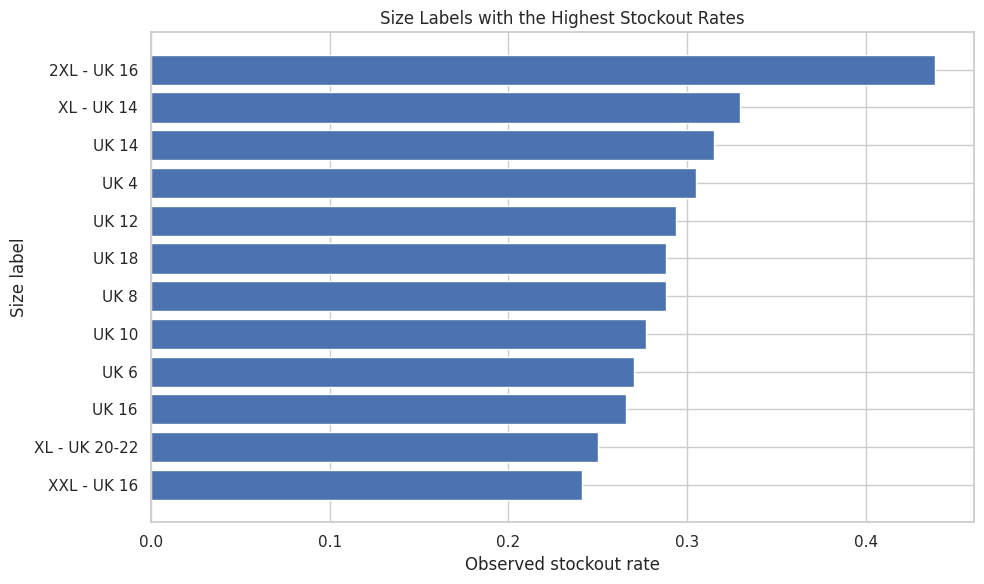

In [13]:
# Explode comma-separated size options into one row per size option.
size_rows = df_clean[["Brand", "name", "price", "size"]].copy()
size_rows["size_entry"] = size_rows["size"].fillna("").astype(str).str.split(",")
size_rows = size_rows.explode("size_entry")
size_rows["size_entry"] = size_rows["size_entry"].astype(str).str.strip()
size_rows = size_rows[size_rows["size_entry"].ne("")].copy()

size_rows["Is_Stockout"] = size_rows["size_entry"].str.contains(
    "out of stock", case=False, na=False
)

# Remove the stockout suffix to obtain a comparable size label.
size_rows["Size_Label"] = (
    size_rows["size_entry"]
    .str.replace(r"\s*-\s*Out of stock", "", regex=True, case=False)
    .str.strip()
)

size_summary = (
    size_rows.groupby("Size_Label")
    .agg(
        Size_Option_Records=("Is_Stockout", "size"),
        Sold_Out_Records=("Is_Stockout", "sum"),
        Brands=("Brand", "nunique")
    )
    .reset_index()
)
size_summary["Stockout_Rate"] = (
    size_summary["Sold_Out_Records"] / size_summary["Size_Option_Records"]
)

# Filter rare labels to reduce noise (at least 20 observations).
size_summary_qualified = size_summary[
    size_summary["Size_Option_Records"] >= 20
].sort_values("Stockout_Rate", ascending=False)

print("Size labels with the highest stockout rates (minimum 20 observations):")
display(size_summary_qualified.head(15).style.format({
    "Stockout_Rate": "{:.2%}"
}))

plot_sizes = size_summary_qualified.head(12).sort_values("Stockout_Rate")
if not plot_sizes.empty:
    plt.figure(figsize=(10, 6))
    plt.barh(plot_sizes["Size_Label"], plot_sizes["Stockout_Rate"])
    plt.xlabel("Observed stockout rate")
    plt.ylabel("Size label")
    plt.title("Size Labels with the Highest Stockout Rates")
    plt.tight_layout()
    plt.show()


# *Analysis*

The size-level availability analysis examined stockout patterns across different product size labels, considering only categories with at least 20 observations to ensure a reasonable basis for comparison.

The results revealed that 2XL - UK 16 recorded the highest stockout rate at 43.86%, with 25 out of 57 size-option records marked as sold out. This was followed by XL - UK 14 at 32.98% and UK 14 at 31.52%. These findings indicate that certain size categories experience considerably higher levels of product unavailability than others.

The analysis also identified significant stockout activity among standard UK sizes. UK 12 recorded a stockout rate of 29.35%, while UK 18 and UK 8 registered 28.83% and 28.80%, respectively. This demonstrates that availability concerns are not limited to extended-size categories but are also present across several standard sizing options.

In terms of absolute unavailable records, UK 18 recorded the highest number of sold-out observations at 64, followed by XL - UK 14 with 62 and UK 16 with 60. These results highlight the importance of considering both stockout rates and the actual number of unavailable size records when evaluating inventory performance.

Furthermore, the analysis showed that certain size categories were represented across multiple brands. UK 16 appeared across 19 brands, while UK 18 appeared across 18 brands, suggesting that their availability patterns extend across a broader portion of the analyzed brand assortment.

Overall, the findings indicate that product availability varies considerably across size categories. ASOS should therefore consider incorporating size-specific demand patterns and stockout performance into its inventory allocation and replenishment strategies. Particular attention should be given to sizes with elevated stockout rates and high numbers of unavailable records to support a more balanced and responsive inventory management approach.

# 8. Product Prioritization Matrix

Products are classified using the 75th percentile of their stockout rate and exposure proxy. This relative approach avoids choosing arbitrary universal cutoffs. The matrix is a screening tool: it highlights products for review.

,Priority,Product_Count
0,Routine monitoring,366
1,High priority,109
2,Medium priority,50


Top products for inventory investigation:


,Brand,name,Avg_Price,Listing_Rows,Avg_Stockout_Rate,Exposure_Proxy,Priority
385,The North FaceStand out,The North Face 1996 Retro Nuptse down jacket in lilac paint print,300.00,1,80.00%,"1,200.00",High priority
64,ASOS DESIGNDramatic entrance,ASOS DESIGN embellished plunge mini dress in ombre beaded fringe in taupe,165.00,1,87.50%,"1,155.00",High priority
166,ASOS EDITIONIf in doubt,ASOS EDITION sequin and faux feather fringe midi dress in lilac,205.00,1,62.50%,"1,025.00",High priority
175,ASOS LuxeIf in doubt,ASOS LUXE embellished sequin mini dress with heart back cut out & feather trim in pink,100.00,1,87.50%,700.00,High priority
399,The North FaceStand out,The North Face Saikuru puffer jacket in blue,215.00,1,60.00%,645.00,High priority
46,ASOS DESIGNThanks,ASOS DESIGN Bridesmaid ruched bodice drape maxi dress with wrap waist and flutter cape sleeve in forest green,85.00,1,87.50%,595.00,High priority
66,ASOS DESIGNIf in doubt,ASOS DESIGN embellished shift mini dress with beaded fringe in black,145.00,1,50.00%,580.00,High priority
354,River IslandThrow on,River Island belted funnel neck tailored coat in beige,95.00,1,85.71%,570.00,High priority
360,River IslandThrow on,River Island wrap coat in dark khaki,95.00,1,85.71%,570.00,High priority
163,ASOS EDITIONIf in doubt,ASOS EDITION blocked chevron sequin fringe mini dress,140.00,1,50.00%,560.00,High priority


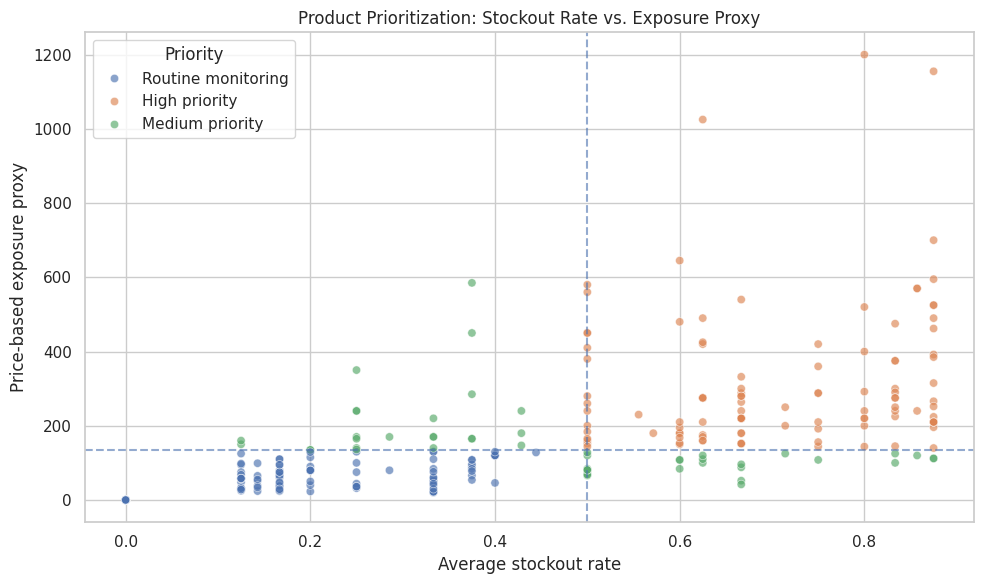

In [14]:
# product_analysis was consolidated in the brand-analysis section above.

stockout_cutoff = product_analysis["Avg_Stockout_Rate"].quantile(0.75)
exposure_cutoff = product_analysis["Exposure_Proxy"].quantile(0.75)

def assign_priority(row):
    high_stockout = row["Avg_Stockout_Rate"] >= stockout_cutoff
    high_exposure = row["Exposure_Proxy"] >= exposure_cutoff
    if high_stockout and high_exposure:
        return "High priority"
    if high_stockout or high_exposure:
        return "Medium priority"
    return "Routine monitoring"

product_analysis["Priority"] = product_analysis.apply(assign_priority, axis=1)

priority_summary = (
    product_analysis["Priority"].value_counts()
    .rename_axis("Priority")
    .reset_index(name="Product_Count")
)
display(priority_summary)

priority_products = (
    product_analysis[product_analysis["Priority"] == "High priority"]
    .sort_values(["Exposure_Proxy", "Avg_Stockout_Rate"], ascending=False)
    .head(20)
)

print("Top products for inventory investigation:")
display(priority_products[[
    "Brand", "name", "Avg_Price", "Listing_Rows",
    "Avg_Stockout_Rate", "Exposure_Proxy", "Priority"
]].style.format({
    "Avg_Price": "{:,.2f}",
    "Avg_Stockout_Rate": "{:.2%}",
    "Exposure_Proxy": "{:,.2f}"
}))

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=product_analysis,
    x="Avg_Stockout_Rate",
    y="Exposure_Proxy",
    hue="Priority",
    alpha=0.65
)
plt.axvline(stockout_cutoff, linestyle="--", alpha=0.6)
plt.axhline(exposure_cutoff, linestyle="--", alpha=0.6)
plt.xlabel("Average stockout rate")
plt.ylabel("Price-based exposure proxy")
plt.title("Product Prioritization: Stockout Rate vs. Exposure Proxy")
plt.tight_layout()
plt.show()


# *Analysis*

The product prioritization analysis classified 525 unique products into three inventory management categories based on their stockout performance and estimated financial exposure. The results showed that 366 products (69.71%) were assigned to routine monitoring, 109 products (20.76%) were classified as high priority, and 50 products (9.52%) were categorized as medium priority.

The findings indicate that while the majority of products fall under routine monitoring, approximately one-fifth of the analyzed assortment requires closer inventory investigation. This provides ASOS with a structured approach to identifying products that may require more immediate inventory management attention.

Among the products identified for further investigation, The North Face 1996 Retro Nuptse down jacket in lilac paint print recorded the highest estimated exposure proxy of 1,200.00, with an average listed price of 300.00 and an average stockout rate of 80.00%. This was followed by the ASOS DESIGN embellished plunge mini dress in ombre beaded fringe in taupe, which recorded an 87.50% stockout rate and an estimated exposure proxy of 1,155.00. Other notable products included the ASOS EDITION sequin and faux feather fringe midi dress, with an estimated exposure of 1,025.00, and the ASOS LUXE embellished sequin mini dress, with an estimated exposure of 700.00.

The top-priority products also included several outerwear items from brands such as The North Face, River Island, New Look, and Vila, alongside fashion and occasionwear products from ASOS DESIGN, ASOS EDITION, and ASOS LUXE. This demonstrates that significant availability concerns occur across different product types and price segments.

Overall, the product prioritization matrix provides a practical basis for directing inventory management efforts toward products with more concerning availability and exposure characteristics. ASOS should prioritize investigating the 109 high-priority products, regularly monitor the 50 medium-priority products, and maintain routine availability checks for the remaining assortment. This approach can support more efficient inventory monitoring, targeted replenishment investigations, and improved product availability management.

# **Recommendations**

Based on the findings from the product-level consolidation, brand strategy analysis, size-level availability analysis, and product prioritization matrix, several business recommendations are proposed to help ASOS improve product availability, strengthen inventory management, and minimize potential missed sales opportunities.

The analysis identified that stockout concerns exist across different products, brands, and size categories. Approximately 23.98% of the recorded size options were unavailable, while 50.41% of analyzed products experienced at least one stockout. Furthermore, 109 out of 525 unique products (20.76%) were classified as high priority, indicating the need for targeted inventory investigation.

The findings suggest that ASOS should adopt an integrated, data-driven inventory management strategy that considers product availability at the product, brand, and size levels.

Rather than relying exclusively on individual stockout rates or product prices, management should combine these indicators with product assortment size and estimated financial exposure to determine which inventory concerns deserve attention first.

The immediate priority should be to investigate the 109 high-priority products, particularly those with substantial stockout rates and estimated exposure. At the same time, ASOS should examine the availability of frequently unavailable sizes and investigate brands demonstrating elevated stockout performance.

In the medium term, management should establish consistent inventory monitoring procedures, improve size-level allocation decisions, and strengthen coordination with suppliers. In the longer term, the company should consider integrating predictive analytics into its inventory planning processes to anticipate potential stock shortages and support more effective replenishment decisions.

Ultimately, the objective is to move ASOS from reactive stockout management toward a proactive and evidence-based inventory management approach that improves product availability, supports more efficient inventory decisions, and reduces potential missed sales opportunities.
